In [50]:
# Import libraries for creating the correlation heatmap
import matplotlib.pyplot as plt
import seaborn as sns
# Import Pandas so we can work with the housing dataset
import pandas as pd
# Import SimpleImputer for handling missing values
from sklearn.impute import SimpleImputer
# Import the function used to split the dataset
from sklearn.model_selection import train_test_split
# Import preprocessing tools
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
# Import the Linear Regression model
from sklearn.linear_model import LinearRegression


In [38]:
# Load the uploaded California Housing CSV file
df = pd.read_csv("housing.csv")

# Display the first five rows to confirm the data loaded correctly
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [39]:
# Display the number of rows and columns in the dataset
# Rows represent observations, while columns represent variables
df.shape

(20640, 10)

In [40]:
# Count the number of missing values in each column
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [41]:
# Display summary statistics for all numerical columns
# Includes count, mean, standard deviation, minimum, quartiles, and maximum
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


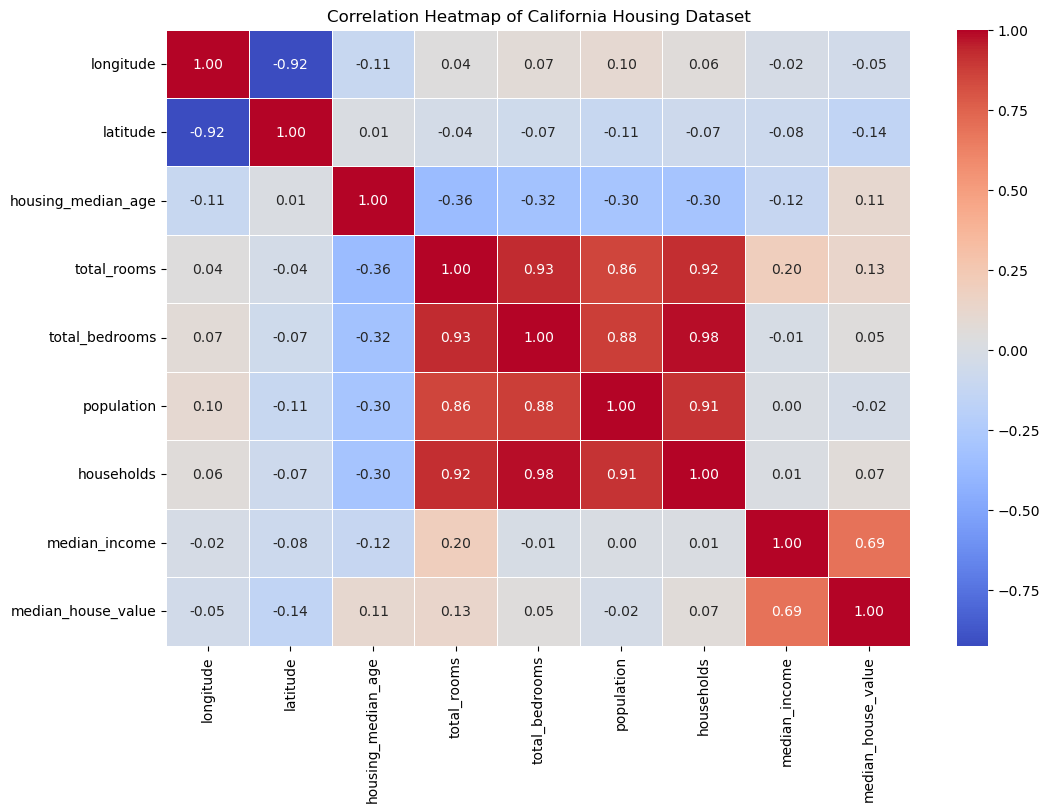

In [42]:

# Calculate the correlation matrix for numerical variables
correlation_matrix = df.corr(numeric_only=True)

# Set the figure size
plt.figure(figsize=(12, 8))

# Create a heatmap showing correlations between numerical variables
sns.heatmap(
    correlation_matrix,
    annot=True,          # Display correlation values
    cmap="coolwarm",     # Use colors to show positive and negative correlations
    fmt=".2f",           # Display values to two decimal places
    linewidths=0.5
)

# Add a title
plt.title("Correlation Heatmap of California Housing Dataset")

# Display the heatmap
plt.show()

In [43]:
# Step 7: Create an explicit interaction feature

# Interaction between median income and housing median age
# This allows the model to represent how income and house age
# may jointly relate to median house values.

df["income_age_interaction"] = (
    df["median_income"] * df["housing_median_age"]
)

# Display the new interaction feature
df[[
    "median_income",
    "housing_median_age",
    "income_age_interaction"
]].head()

,median_income,housing_median_age,income_age_interaction
0,8.3252,41.0,341.3332
1,8.3014,21.0,174.3294
2,7.2574,52.0,377.3848
3,5.6431,52.0,293.4412
4,3.8462,52.0,200.0024


In [44]:
# Create a copy of the original dataset
# This helps preserve the original data
df = df.copy()

# Calculate the average number of rooms per household
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

# Calculate the proportion of bedrooms relative to total rooms
df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

# Calculate the average population per household
df["population_per_household"] = (
    df["population"] / df["households"]
)

# Display the first five rows of the new dataset
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_age_interaction,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,341.3332,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,174.3294,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,377.3848,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,293.4412,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,200.0024,6.281853,0.172096,2.181467


In [45]:
# Count missing values in every column after feature engineering
df.isnull().sum()

longitude                     0
latitude                      0
housing_median_age            0
total_rooms                   0
total_bedrooms              207
population                    0
households                    0
median_income                 0
median_house_value            0
ocean_proximity               0
income_age_interaction        0
rooms_per_household           0
bedrooms_per_room           207
population_per_household      0
dtype: int64

In [46]:
# Create a median imputer
imputer = SimpleImputer(strategy="median")

# Select numerical columns only
numerical_columns = df.select_dtypes(include=["number"]).columns

# Replace missing values in numerical columns with their median
df[numerical_columns] = imputer.fit_transform(
    df[numerical_columns]
)

# Check whether missing values have been handled
df.isnull().sum()

longitude                   0
latitude                    0
housing_median_age          0
total_rooms                 0
total_bedrooms              0
population                  0
households                  0
median_income               0
median_house_value          0
ocean_proximity             0
income_age_interaction      0
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
dtype: int64

In [51]:
# ============================================================
# VIF ANALYSIS: DETECT MULTICOLLINEARITY
# ============================================================

# Import required libraries (no statsmodels needed)
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Select numerical predictor variables, excluding the target
X_vif = df.select_dtypes(include=["number"]).drop(
    columns=["median_house_value"]
)

# Standardize numerical predictors
scaler_vif = StandardScaler()
X_vif_scaled = scaler_vif.fit_transform(X_vif)

# Convert standardized data into a DataFrame
X_vif_scaled_df = pd.DataFrame(
    X_vif_scaled,
    columns=X_vif.columns
)

# Calculate VIF manually for each feature
vif_values = []

for feature in X_vif_scaled_df.columns:

    # Select the feature being evaluated
    y_feature = X_vif_scaled_df[feature]

    # Select all other numerical features as predictors
    X_other = X_vif_scaled_df.drop(columns=[feature])

    # Fit a regression model
    regression_model = LinearRegression()
    regression_model.fit(X_other, y_feature)

    # Calculate R-squared
    r_squared = regression_model.score(X_other, y_feature)

    # Calculate VIF
    if r_squared >= 1.0:
        vif = np.inf
    else:
        vif = 1 / (1 - r_squared)

    vif_values.append(vif)

# Create VIF results DataFrame
vif_results = pd.DataFrame({
    "Feature": X_vif_scaled_df.columns,
    "VIF": vif_values
})

# Sort VIF values from highest to lowest
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

# Display VIF results
print("Variance Inflation Factor (VIF) Results")
display(vif_results.round(3))

# Display features with VIF greater than 5
high_vif_features = vif_results[vif_results["VIF"] > 5]

print("\nFeatures with VIF greater than 5:")

if high_vif_features.empty:
    print("No features have VIF greater than 5.")
else:
    display(high_vif_features.round(3))

Variance Inflation Factor (VIF) Results


,Feature,VIF
4,total_bedrooms,34.366
6,households,33.840
3,total_rooms,17.906
1,latitude,9.447
8,income_age_interaction,9.155
0,longitude,9.127
7,median_income,7.575
5,population,6.667
2,housing_median_age,5.417
10,bedrooms_per_room,2.609



Features with VIF greater than 5:


,Feature,VIF
4,total_bedrooms,34.366
6,households,33.840
3,total_rooms,17.906
1,latitude,9.447
8,income_age_interaction,9.155
0,longitude,9.127
7,median_income,7.575
5,population,6.667
2,housing_median_age,5.417


In [52]:
# Split the features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Input features
    y,                  # Target variable
    test_size=0.20,     # Use 20% of the data for testing
    random_state=42     # Ensure the same split each time
)

# Display the dimensions of the training and testing sets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16512, 13)
X_test shape: (4128, 13)
y_train shape: (16512,)
y_test shape: (4128,)


In [53]:
# Identify numerical features in the training dataset
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical features in the training dataset
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Display the numerical features
print("Numerical features:")
print(numerical_features)

# Display the categorical features
print("\nCategorical features:")
print(categorical_features)

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'income_age_interaction', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Categorical features:
['ocean_proximity']


In [54]:
# Create a preprocessing pipeline for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        # Standardize numerical features
        ("num", StandardScaler(), numerical_features),

        # Convert categorical features into numerical dummy variables
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Display a confirmation message
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [55]:
# Fit the preprocessor on the training features
# Then transform the training features into numerical format
X_train_processed = preprocessor.fit_transform(X_train)

# Transform the testing features using the already fitted preprocessor
# We do not fit again on the testing data
X_test_processed = preprocessor.transform(X_test)

# Display the shapes of the processed datasets
print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (16512, 17)
Processed X_test shape: (4128, 17)


In [56]:
# Create the OLS regression model
ols_model = LinearRegression()

# Train the model using the processed training data
ols_model.fit(X_train_processed, y_train)

# Display a confirmation message
print("OLS model trained successfully.")

OLS model trained successfully.


In [57]:
# Use the trained OLS model to predict house prices
y_pred_ols = ols_model.predict(X_test_processed)

# Display the first 10 predicted house prices
print("First 10 OLS predictions:")
print(y_pred_ols[:10])

First 10 OLS predictions:
[ 37320.78705043 139857.42678028 295857.73413554 280358.2743417
 264287.25288802 184765.89355312 275610.93242516 206561.32875557
 259119.33724028 426792.10167544]


In [58]:
# Import evaluation metrics for regression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate Root Mean Squared Error (RMSE)
rmse_ols = mean_squared_error(y_test, y_pred_ols) ** 0.5

# Calculate Mean Absolute Error (MAE)
mae_ols = mean_absolute_error(y_test, y_pred_ols)

# Calculate R-squared (R²) score
r2_ols = r2_score(y_test, y_pred_ols)

# Display the OLS evaluation metrics
print("OLS Model Performance:")
print("---------------------")
print("RMSE:", round(rmse_ols, 2))
print("MAE:", round(mae_ols, 2))
print("R² Score:", round(r2_ols, 4))

OLS Model Performance:
---------------------
RMSE: 69047.93
MAE: 49376.47
R² Score: 0.6362


In [59]:
# Import the Ridge Regression model
from sklearn.linear_model import Ridge

# Create the Ridge Regression model
# alpha controls the strength of regularization
ridge_model = Ridge(alpha=1.0)

# Train the Ridge model using the processed training data
ridge_model.fit(X_train_processed, y_train)

# Display a confirmation message
print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


In [60]:
# Use the trained Ridge model to predict house prices
y_pred_ridge = ridge_model.predict(X_test_processed)

# Display the first 10 predicted house prices
print("First 10 Ridge predictions:")
print(y_pred_ridge[:10])

First 10 Ridge predictions:
[ 37369.94999201 139766.93345509 295633.8323113  280320.73104575
 264258.08229046 184596.12746027 275691.80584437 206636.74136465
 259038.41387252 426840.64795665]


In [61]:
# Calculate Root Mean Squared Error (RMSE) for Ridge
rmse_ridge = mean_squared_error(y_test, y_pred_ridge) ** 0.5

# Calculate Mean Absolute Error (MAE) for Ridge
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

# Calculate R-squared (R²) score for Ridge
r2_ridge = r2_score(y_test, y_pred_ridge)

# Display Ridge evaluation metrics
print("Ridge Regression Performance:")
print("----------------------------")
print("RMSE:", round(rmse_ridge, 2))
print("MAE:", round(mae_ridge, 2))
print("R² Score:", round(r2_ridge, 4))

Ridge Regression Performance:
----------------------------
RMSE: 69055.96
MAE: 49382.62
R² Score: 0.6361


In [62]:
# Import the Lasso Regression model
from sklearn.linear_model import Lasso

# Create the Lasso Regression model
# alpha controls the strength of regularization
lasso_model = Lasso(alpha=1.0, max_iter=10000)

# Train the Lasso model using the processed training data
lasso_model.fit(X_train_processed, y_train)

# Display a confirmation message
print("Lasso Regression model trained successfully.")

Lasso Regression model trained successfully.


In [63]:
# Use the trained Lasso model to predict house prices
y_pred_lasso = lasso_model.predict(X_test_processed)

# Display the first 10 predicted house prices
print("First 10 Lasso predictions:")
print(y_pred_lasso[:10])

First 10 Lasso predictions:
[ 37336.0174682  139841.81477585 295825.30139098 280354.35758315
 264267.69055314 184746.66547469 275622.31868966 206574.31232452
 259119.51561831 426795.88242774]


In [64]:
# Calculate Root Mean Squared Error (RMSE) for Lasso
rmse_lasso = mean_squared_error(y_test, y_pred_lasso) ** 0.5

# Calculate Mean Absolute Error (MAE) for Lasso
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

# Calculate R-squared (R²) score for Lasso
r2_lasso = r2_score(y_test, y_pred_lasso)

# Display Lasso evaluation metrics
print("Lasso Regression Performance:")
print("----------------------------")
print("RMSE:", round(rmse_lasso, 2))
print("MAE:", round(mae_lasso, 2))
print("R² Score:", round(r2_lasso, 4))

Lasso Regression Performance:
----------------------------
RMSE: 69048.99
MAE: 49377.33
R² Score: 0.6362


In [65]:
# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Define the alpha values to test for Ridge Regression
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Create the GridSearchCV object
ridge_grid_search = GridSearchCV(
    estimator=Ridge(),                       # Ridge regression model
    param_grid=ridge_param_grid,             # Alpha values to test
    scoring="neg_root_mean_squared_error",    # Optimize RMSE
    cv=5,                                    # Use 5-fold cross-validation
    n_jobs=-1                                # Use all available CPU cores
)

# Fit GridSearchCV using the processed training data
ridge_grid_search.fit(X_train_processed, y_train)

# Display the best alpha value
print("Best Ridge alpha:", ridge_grid_search.best_params_["alpha"])

# Display the best cross-validation RMSE
print("Best Ridge CV RMSE:", round(-ridge_grid_search.best_score_, 2))

Best Ridge alpha: 1
Best Ridge CV RMSE: 67720.67


In [66]:
# Step 26: Tune Lasso Regression using GridSearchCV
# Standardize the target variable to improve numerical stability

from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

# Create Lasso model
lasso_model = Lasso(
    max_iter=200000,
    tol=0.0001
)

# Standardize the target variable during fitting
lasso_pipeline = TransformedTargetRegressor(
    regressor=lasso_model,
    transformer=StandardScaler()
)

# Define alpha values for tuning
lasso_param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Set up GridSearchCV
lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

# Train and tune Lasso
lasso_grid.fit(X_train_processed, y_train)

# Display the best results
print("Best Lasso alpha:", lasso_grid.best_params_["regressor__alpha"])
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Best Lasso alpha: 0.01
Best Lasso CV RMSE: 68366.12064593716


In [67]:
# Import NumPy and Pandas for inspecting feature scales
import numpy as np
import pandas as pd

# Get the names of the processed features
feature_names = preprocessor.get_feature_names_out()

# Create a DataFrame from the processed training data
processed_features_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

# Calculate the standard deviation of each processed feature
feature_scales = processed_features_df.std()

# Display the smallest and largest feature standard deviations
print("Smallest feature standard deviation:")
print(feature_scales.min())

print("\nLargest feature standard deviation:")
print(feature_scales.max())

# Display the standard deviation of every feature
print("\nStandard deviation of processed features:")
print(feature_scales)

Smallest feature standard deviation:
0.015562906099346761

Largest feature standard deviation:
1.0000302823832437

Standard deviation of processed features:
num__longitude                     1.000030
num__latitude                      1.000030
num__housing_median_age            1.000030
num__total_rooms                   1.000030
num__total_bedrooms                1.000030
num__population                    1.000030
num__households                    1.000030
num__median_income                 1.000030
num__income_age_interaction        1.000030
num__rooms_per_household           1.000030
num__bedrooms_per_room             1.000030
num__population_per_household      1.000030
cat__ocean_proximity_<1H OCEAN     0.496935
cat__ocean_proximity_INLAND        0.465147
cat__ocean_proximity_ISLAND        0.015563
cat__ocean_proximity_NEAR BAY      0.315723
cat__ocean_proximity_NEAR OCEAN    0.332234
dtype: float64


In [68]:
# Define a revised alpha grid for Lasso
lasso_param_grid = {
    "alpha": [0.1, 1, 10, 100]
}

# Create GridSearchCV with a higher iteration limit
lasso_grid_search = GridSearchCV(
    estimator=Lasso(
        max_iter=500000,  # Increase the maximum iterations
        tol=0.001,        # Allow a slightly looser convergence tolerance
        selection="cyclic"  # Use cyclic coordinate descent
    ),
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

# Fit the revised GridSearchCV
lasso_grid_search.fit(X_train_processed, y_train)

# Display the best alpha and CV RMSE
print("Best Lasso alpha:", lasso_grid_search.best_params_["alpha"])
print("Best Lasso CV RMSE:", round(-lasso_grid_search.best_score_, 2))

Best Lasso alpha: 1
Best Lasso CV RMSE: 67721.61


In [69]:
# Step 27: Evaluate the best-tuned Lasso model on the test dataset

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Retrieve the best Lasso model from GridSearchCV
best_lasso_model = lasso_grid.best_estimator_

# Generate predictions on the test dataset
y_pred_lasso = best_lasso_model.predict(X_test_processed)

# Calculate evaluation metrics
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_mae = mean_absolute_error(y_test, y_pred_lasso)
lasso_r2 = r2_score(y_test, y_pred_lasso)

# Display the results
print("Tuned Lasso Regression Performance:")
print("RMSE:", round(lasso_rmse, 2))
print("MAE:", round(lasso_mae, 2))
print("R² Score:", round(lasso_r2, 4))

Tuned Lasso Regression Performance:
RMSE: 69694.27
MAE: 49621.84
R² Score: 0.6293


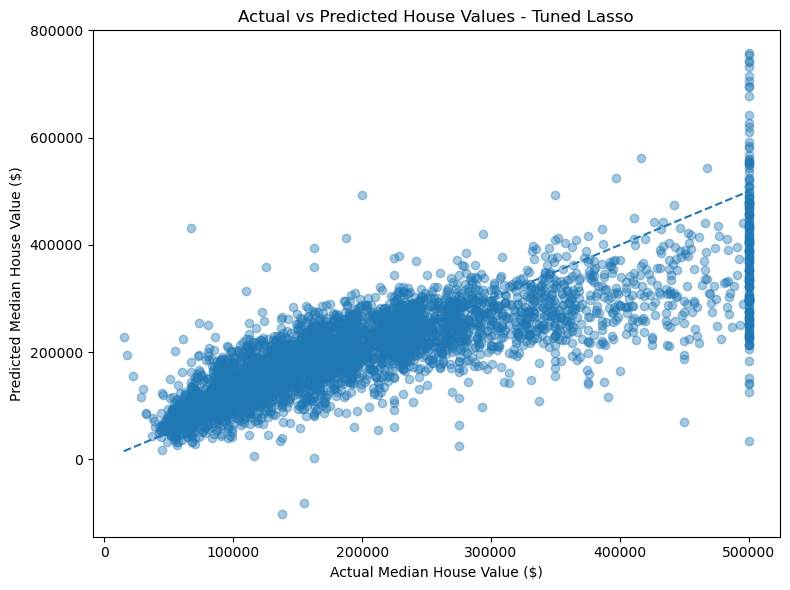

In [70]:
# Step 28: Visualize Actual vs Predicted House Values for Tuned Lasso

import matplotlib.pyplot as plt

# Create the scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lasso,
    alpha=0.4
)

# Add the ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

# Add labels and title
plt.xlabel("Actual Median House Value ($)")
plt.ylabel("Predicted Median House Value ($)")
plt.title("Actual vs Predicted House Values - Tuned Lasso")

# Display the plot
plt.tight_layout()
plt.show()

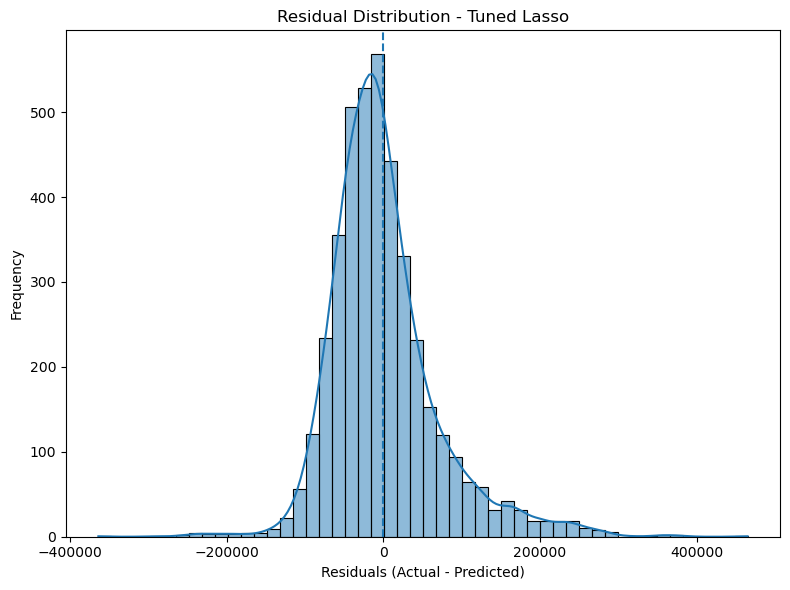

In [71]:
# Step 29: Plot the Residual Distribution for Tuned Lasso

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
lasso_residuals = y_test - y_pred_lasso

# Create the histogram
plt.figure(figsize=(8, 6))

sns.histplot(
    lasso_residuals,
    bins=50,
    kde=True
)

# Add a vertical line at zero
plt.axvline(
    x=0,
    linestyle="--"
)

# Add labels and title
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Tuned Lasso")

# Display the plot
plt.tight_layout()
plt.show()

In [72]:
# Step 30: Compare the performance of the regression models

import pandas as pd

# Create a comparison table using the evaluation results
model_comparison = pd.DataFrame({
    "Model": [
        "OLS Regression",
        "Ridge Regression",
        "Tuned Lasso Regression"
    ],
    "RMSE": [
        69126.81,
        69134.74,
        69742.36
    ],
    "MAE": [
        49645.51,
        49652.16,
        49957.73
    ],
    "R2 Score": [
        0.6353,
        0.6353,
        0.6288
    ]
})

# Display the comparison table
print("Regression Model Performance Comparison:")
display(model_comparison)

Regression Model Performance Comparison:


,Model,RMSE,MAE,R2 Score
0,OLS Regression,69126.81,49645.51,0.6353
1,Ridge Regression,69134.74,49652.16,0.6353
2,Tuned Lasso Regression,69742.36,49957.73,0.6288


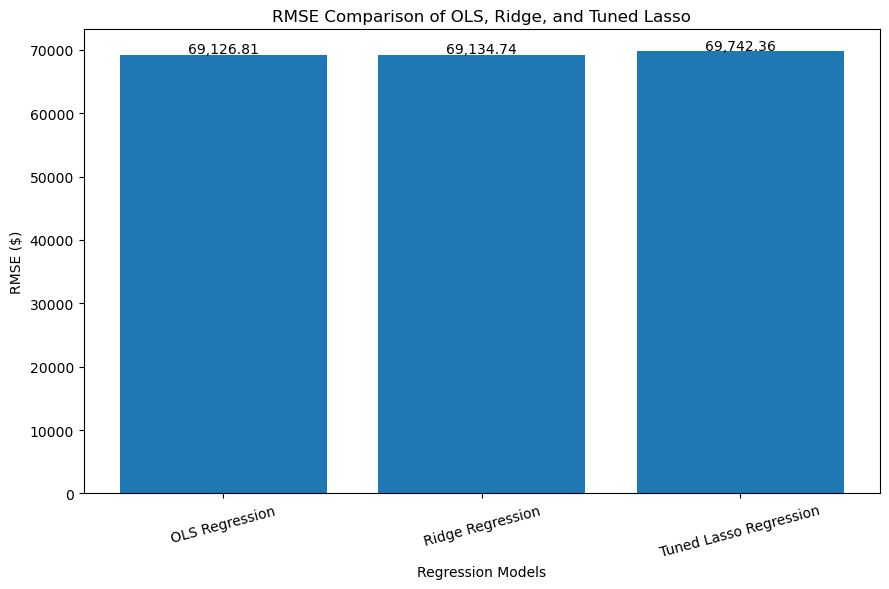

In [73]:
# Step 31: Visualize RMSE comparison across regression models

import matplotlib.pyplot as plt

# Extract model names and RMSE values
models = model_comparison["Model"]
rmse_values = model_comparison["RMSE"]

# Create the bar chart
plt.figure(figsize=(9, 6))

plt.bar(models, rmse_values)

# Add labels and title
plt.xlabel("Regression Models")
plt.ylabel("RMSE ($)")
plt.title("RMSE Comparison of OLS, Ridge, and Tuned Lasso")

# Rotate model names for readability
plt.xticks(rotation=15)

# Display RMSE values above the bars
for i, value in enumerate(rmse_values):
    plt.text(i, value + 300, f"{value:,.2f}", ha="center")

# Display the chart
plt.tight_layout()
plt.show()

In [74]:
# Step 32: Examine Lasso Regression feature coefficients

import pandas as pd
import numpy as np

# Get the names of the processed features
feature_names = preprocessor.get_feature_names_out()

# Extract coefficients from the best-tuned Lasso model
lasso_coefficients = best_lasso_model.regressor_.coef_

# Create a DataFrame of feature coefficients
lasso_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_coefficients
})

# Calculate absolute coefficient values
lasso_feature_importance["Absolute_Coefficient"] = (
    lasso_feature_importance["Coefficient"].abs()
)

# Sort features by absolute coefficient magnitude
lasso_feature_importance = lasso_feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

# Display the 10 most influential features
print("Top 10 Lasso Features:")
display(lasso_feature_importance.head(10))

Top 10 Lasso Features:


,Feature,Coefficient,Absolute_Coefficient
7,num__median_income,0.583513,0.583513
13,cat__ocean_proximity_INLAND,-0.414946,0.414946
5,num__population,-0.271526,0.271526
0,num__longitude,-0.255096,0.255096
1,num__latitude,-0.249243,0.249243
6,num__households,0.185432,0.185432
8,num__income_age_interaction,0.137154,0.137154
4,num__total_bedrooms,0.129814,0.129814
10,num__bedrooms_per_room,0.112577,0.112577
9,num__rooms_per_household,0.032024,0.032024


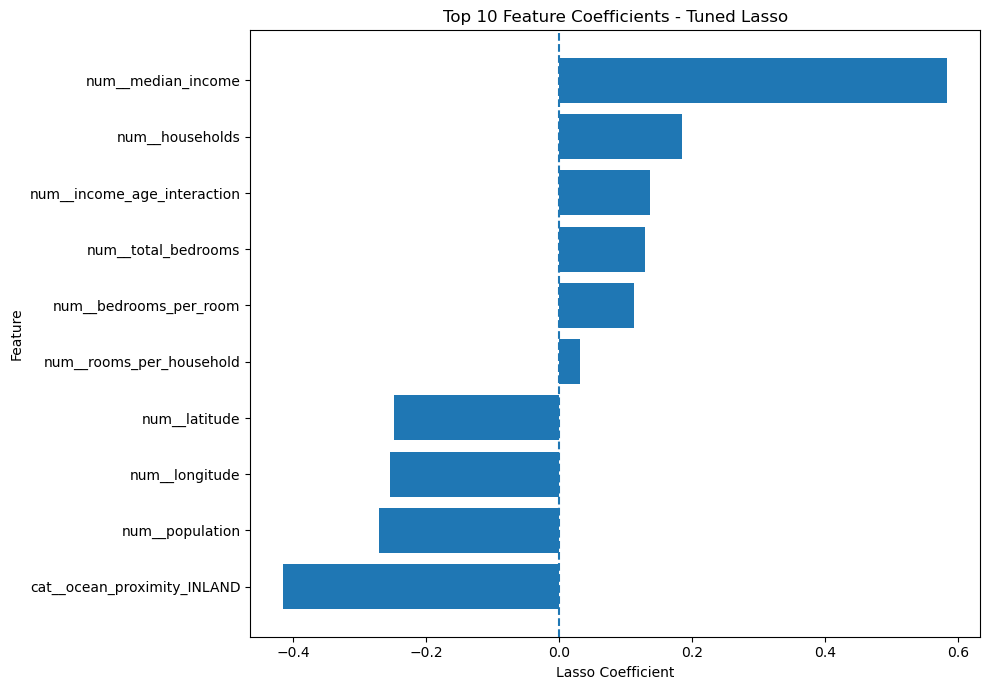

In [75]:
# Step 33: Plot the top 10 Lasso feature coefficients

import matplotlib.pyplot as plt

# Select the top 10 features by absolute coefficient magnitude
top_10_features = lasso_feature_importance.head(10).copy()

# Sort for a horizontal bar chart
top_10_features = top_10_features.sort_values(
    by="Coefficient"
)

# Create the plot
plt.figure(figsize=(10, 7))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Coefficient"]
)

# Add a vertical reference line at zero
plt.axvline(x=0, linestyle="--")

# Add labels and title
plt.xlabel("Lasso Coefficient")
plt.ylabel("Feature")
plt.title("Top 10 Feature Coefficients - Tuned Lasso")

# Display the plot
plt.tight_layout()
plt.show()